# Avengers Face Recognition using CNN
**Innomatics Research Labs – CNN Capstone Project**

## 1. Problem Statement
Build a Convolutional Neural Network that identifies which Avengers actor appears in a cropped face image. This is a **5-class image classification** task:

`Chris Evans · Chris Hemsworth · Mark Ruffalo · Robert Downey Jr · Scarlett Johansson`

**Goal:** train a CNN that generalises to unseen face images, and evaluate it with accuracy, precision, recall, F1-score and a confusion matrix.

**Dataset:** [Avengers Face Recognition (Kaggle)](https://www.kaggle.com/datasets/rawatjitesh/avengers-face-recognition/data), `cropped_images` folder with one sub-folder per class.

> Runtime tip: *Runtime → Change runtime type → T4 GPU* before running.

## 2. Setup & Load Dataset

In [2]:
import os, shutil, hashlib, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings('ignore')
SEED = 42
IMG_SIZE = (128, 128)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from google.colab import drive
drive.mount('/content/drive')

SRC = '/content/drive/MyDrive/cropped_images'
DATA_DIR = '/content/cropped_images'

# Copy to local disk once (much faster than reading from Drive during training)
if not os.path.exists(DATA_DIR):
    shutil.copytree(SRC, DATA_DIR)

# Handle a possible nested folder (cropped_images/cropped_images)
if 'cropped_images' in os.listdir(DATA_DIR):
    DATA_DIR = os.path.join(DATA_DIR, 'cropped_images')

print('Classes found:', sorted(os.listdir(DATA_DIR)))

Mounted at /content/drive
Classes found: ['chris_evans', 'chris_hemsworth', 'mark_ruffalo', 'robert_downey_jr', 'scarlett_johansson']


## 3. Understand the Dataset

In [4]:
rows = []
for cls in sorted(os.listdir(DATA_DIR)):
    p = os.path.join(DATA_DIR, cls)
    if os.path.isdir(p):
        for f in os.listdir(p):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
                rows.append((os.path.join(p, f), cls))

df = pd.DataFrame(rows, columns=['path', 'label'])
print('Total images:', len(df))
print('Number of classes:', df.label.nunique())
df.label.value_counts()

Total images: 274
Number of classes: 5


,count
label,
mark_ruffalo,66
scarlett_johansson,54
chris_hemsworth,53
robert_downey_jr,51
chris_evans,50


In [5]:
def inspect(path):
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            return im.size[0], im.size[1], im.mode, True
    except Exception:
        return None, None, None, False

df[['width', 'height', 'mode', 'valid']] = df.path.apply(lambda p: pd.Series(inspect(p)))
print('Corrupt / unreadable images:', (~df.valid).sum())
df[df.valid][['width', 'height']].describe()

Corrupt / unreadable images: 0


,width,height
count,274.000000,274.000000
mean,267.770073,267.770073
std,254.817327,254.817327
min,58.000000,58.000000
25%,116.250000,116.250000
50%,149.000000,149.000000
75%,324.750000,324.750000
max,1754.000000,1754.000000


## 4. Data Visualization

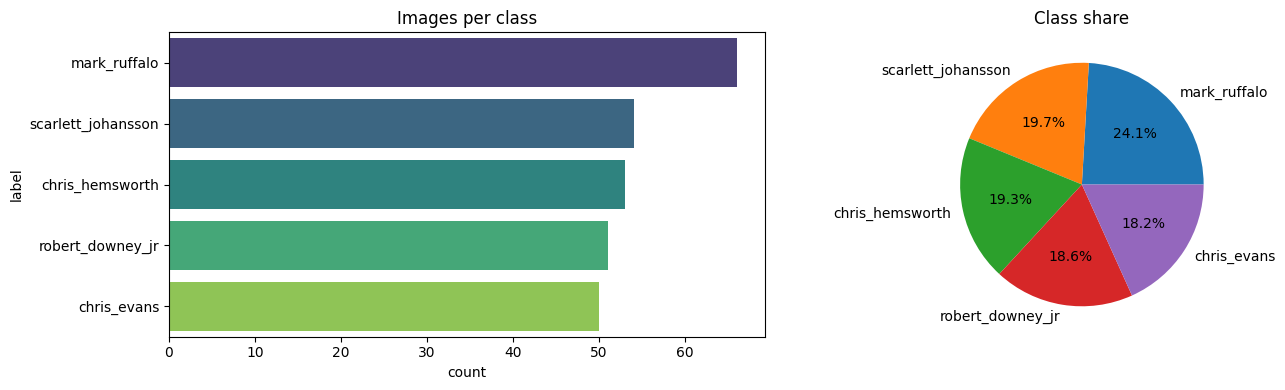

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
order = df.label.value_counts().index
sns.countplot(data=df, y='label', order=order, ax=ax[0], palette='viridis')
ax[0].set_title('Images per class')
df.label.value_counts().plot.pie(autopct='%1.1f%%', ax=ax[1], ylabel='')
ax[1].set_title('Class share')
plt.tight_layout(); plt.show()

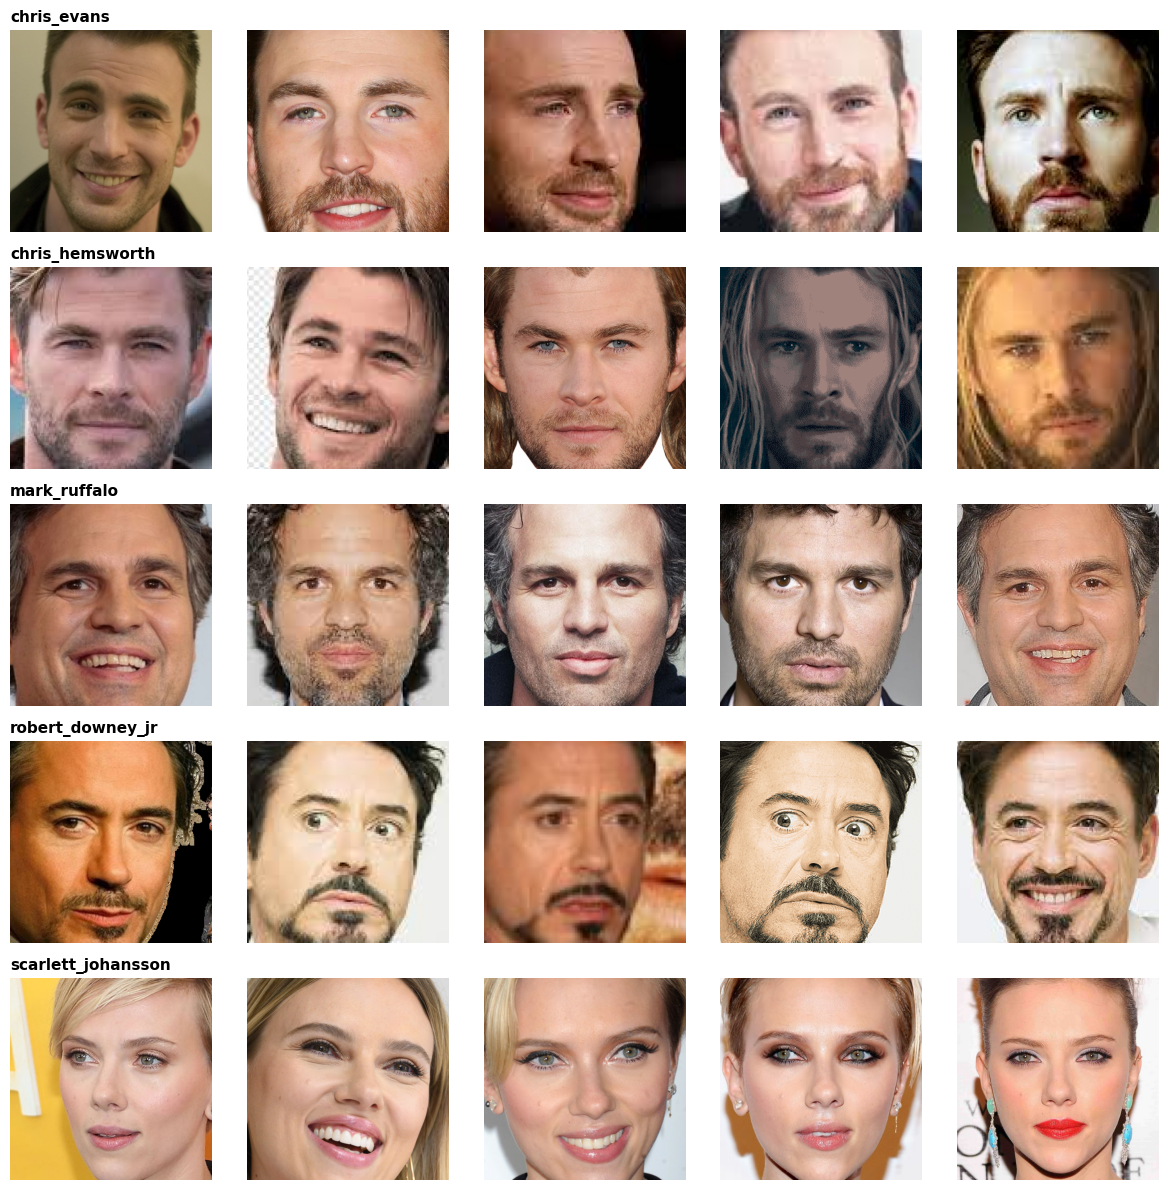

In [7]:
classes = sorted(df.label.unique())
fig, axes = plt.subplots(len(classes), 5, figsize=(12, 2.4 * len(classes)))
for i, cls in enumerate(classes):
    samples = df[(df.label == cls) & df.valid].sample(5, random_state=SEED)
    for j, p in enumerate(samples.path):
        axes[i, j].imshow(Image.open(p).convert('RGB'))
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(cls, loc='left', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

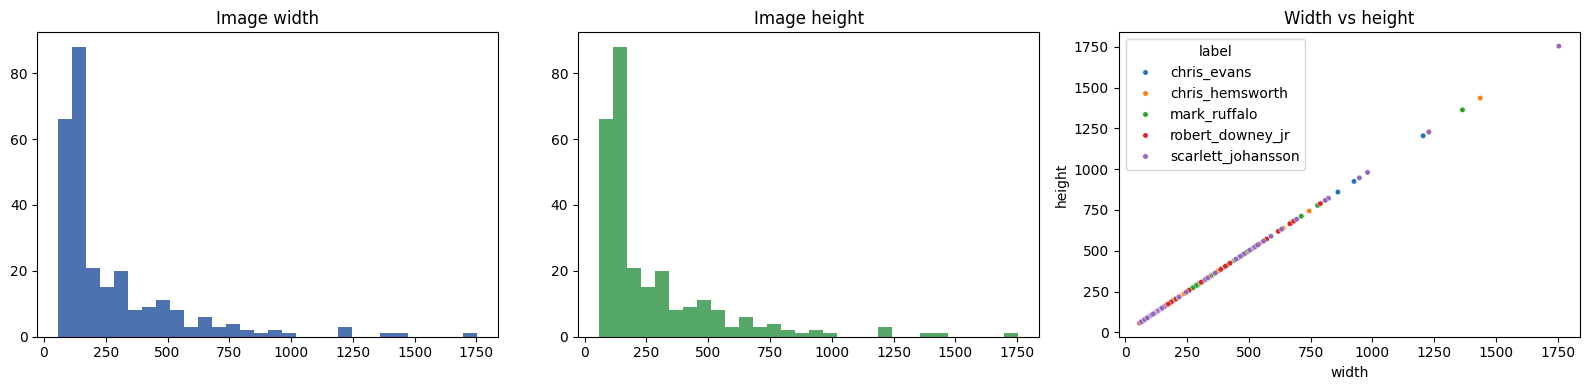

Colour modes: {'RGB': 274}


In [8]:
v = df[df.valid]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(v.width, bins=30, color='#4C72B0'); ax[0].set_title('Image width')
ax[1].hist(v.height, bins=30, color='#55A868'); ax[1].set_title('Image height')
sns.scatterplot(data=v, x='width', y='height', hue='label', s=15, ax=ax[2])
ax[2].set_title('Width vs height')
plt.tight_layout(); plt.show()
print('Colour modes:', v['mode'].value_counts().to_dict())

## 5. Data Cleaning
- **Missing / corrupt values:** drop unreadable images
- **Outliers:** drop extremely small images (too little facial detail)
- **Duplicates:** drop exact duplicate files (they cause train/test leakage)
- **Formatting:** force every image to 3-channel RGB at a fixed size

In [9]:
n0 = len(df)

# 1) corrupt images
df = df[df.valid].copy()
n1 = len(df)

# 2) tiny-image outliers
MIN_SIDE = 40
df = df[(df.width >= MIN_SIDE) & (df.height >= MIN_SIDE)].copy()
n2 = len(df)

# 3) exact duplicates
df['md5'] = df.path.apply(lambda p: hashlib.md5(open(p, 'rb').read()).hexdigest())
df = df.drop_duplicates('md5').copy()
n3 = len(df)

print(f'Start: {n0} | after corrupt removal: {n1} | after tiny removal: {n2} | after dedupe: {n3}')
df = df.reset_index(drop=True)
df.label.value_counts()

Start: 274 | after corrupt removal: 274 | after tiny removal: 274 | after dedupe: 274


,count
label,
mark_ruffalo,66
scarlett_johansson,54
chris_hemsworth,53
robert_downey_jr,51
chris_evans,50


## 6. Data Manipulation: Train / Validation / Test Split
Stratified 70 / 15 / 15 split so every class is represented equally in each subset.

In [10]:
class_names = sorted(df.label.unique())
label2id = {c: i for i, c in enumerate(class_names)}
df['y'] = df.label.map(label2id)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.y, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.y, random_state=SEED)

print('Train:', len(train_df), '| Val:', len(val_df), '| Test:', len(test_df))
pd.DataFrame({'train': train_df.label.value_counts(),
              'val': val_df.label.value_counts(),
              'test': test_df.label.value_counts()})

Train: 191 | Val: 41 | Test: 42


,train,val,test
label,,,
chris_evans,35,7,8
chris_hemsworth,37,8,8
mark_ruffalo,46,10,10
robert_downey_jr,35,8,8
scarlett_johansson,38,8,8


## 7. Preprocessing for Model Building
Resize to 128×128, normalise pixels, build `tf.data` pipelines, and add augmentation (training only, applied inside the model).

In [11]:
def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

def make_ds(d, training=False):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.y.values))
    if training:
        ds = ds.shuffle(len(d), seed=SEED)
    return ds.map(load_img, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)   # not shuffled, so predictions line up with test_df

weights = compute_class_weight('balanced', classes=np.arange(len(class_names)), y=train_df.y.values)
class_weight = dict(enumerate(weights))
print('Class weights:', {class_names[k]: round(v, 2) for k, v in class_weight.items()})

augment = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name='augmentation')

Class weights: {'chris_evans': np.float64(1.09), 'chris_hemsworth': np.float64(1.03), 'mark_ruffalo': np.float64(0.83), 'robert_downey_jr': np.float64(1.09), 'scarlett_johansson': np.float64(1.01)}


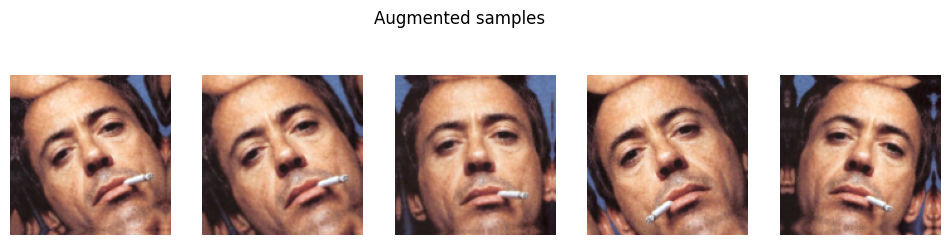

In [12]:
# Preview augmentation
imgs, _ = next(iter(train_ds))
plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(augment(imgs[:1], training=True)[0].numpy().astype('uint8'))
    plt.axis('off')
plt.suptitle('Augmented samples'); plt.show()

## 8. Model Building: CNN Architecture

In [13]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(0.25)(x)

inputs = layers.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = layers.Rescaling(1. / 255)(x)
for f in (32, 64, 128, 256):
    x = conv_block(x, f)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)

model = models.Model(inputs, outputs, name='avengers_cnn')
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "avengers_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,242,213 (4.74 MB)

 Trainable params: 1,240,293 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 9. Training

In [14]:
cbs = [
    callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1),
    callbacks.ModelCheckpoint('/content/best_cnn.keras', monitor='val_accuracy', save_best_only=True),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=60,
                    class_weight=class_weight, callbacks=cbs)

Epoch 1/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 14s 738ms/step - accuracy: 0.1309 - loss: 2.0275 - val_accuracy: 0.2195 - val_loss: 1.6114 - learning_rate: 0.0010
Epoch 2/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 173ms/step - accuracy: 0.3037 - loss: 1.6965 - val_accuracy: 0.1951 - val_loss: 1.6230 - learning_rate: 0.0010
Epoch 3/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - accuracy: 0.2880 - loss: 1.6857 - val_accuracy: 0.1951 - val_loss: 1.6664 - learning_rate: 0.0010
Epoch 4/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 150ms/step - accuracy: 0.3403 - loss: 1.5380 - val_accuracy: 0.1707 - val_loss: 1.6876 - learning_rate: 0.0010
Epoch 5/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.3241 - loss: 1.5434
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 140ms/step - accuracy: 0.3194 - loss: 1.5185 - val_accuracy: 0.1463 - val_loss: 1.7727 - learning_rate: 0.0010
Epoch 6/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 139ms/step - accuracy: 0.3717 - loss: 1.3864 - val_accuracy: 

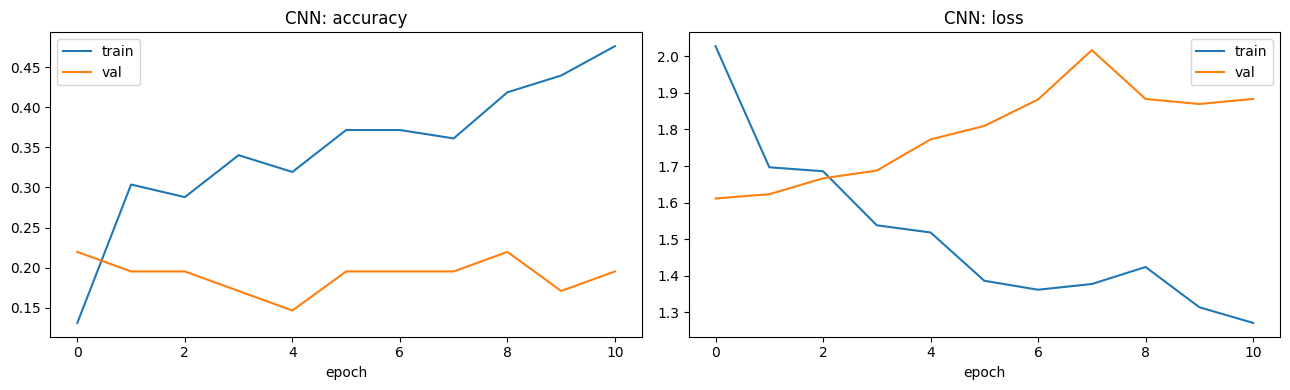

In [15]:
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(h.history['accuracy'], label='train'); ax[0].plot(h.history['val_accuracy'], label='val')
    ax[0].set_title(f'{title}: accuracy'); ax[0].set_xlabel('epoch'); ax[0].legend()
    ax[1].plot(h.history['loss'], label='train'); ax[1].plot(h.history['val_loss'], label='val')
    ax[1].set_title(f'{title}: loss'); ax[1].set_xlabel('epoch'); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(history, 'CNN')

## 10. Evaluation (on the unseen test set)

CNN test accuracy: 0.1905 | test loss: 1.6114

                    precision    recall  f1-score   support

       chris_evans      0.172     0.625     0.270         8
   chris_hemsworth      0.000     0.000     0.000         8
      mark_ruffalo      0.000     0.000     0.000        10
  robert_downey_jr      0.000     0.000     0.000         8
scarlett_johansson      0.231     0.375     0.286         8

          accuracy                          0.190        42
         macro avg      0.081     0.200     0.111        42
      weighted avg      0.077     0.190     0.106        42



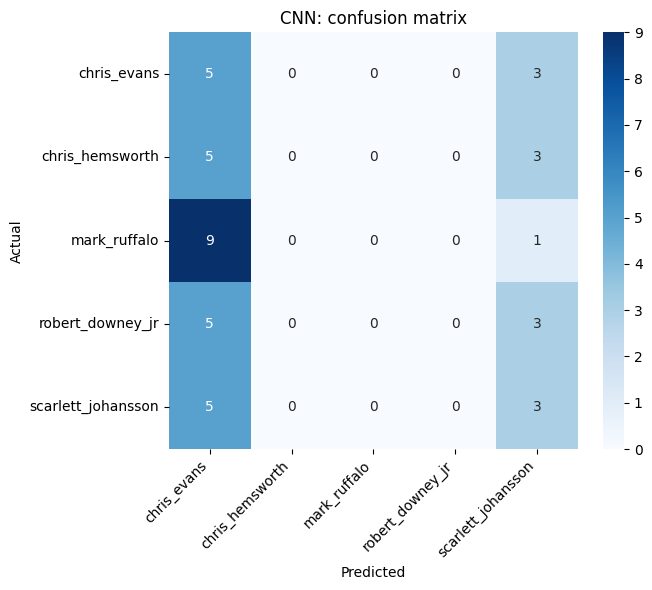

In [19]:
def evaluate(m, name):
    loss, acc = m.evaluate(test_ds, verbose=0)
    print(f'{name} test accuracy: {acc:.4f} | test loss: {loss:.4f}\n')
    probs = m.predict(test_ds, verbose=0)
    y_pred = probs.argmax(1)
    y_true = test_df.y.values
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'{name}: confusion matrix')
    plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()
    return y_true, y_pred, probs

y_true, y_pred, probs = evaluate(model, 'CNN')

Misclassified: 34 of 42


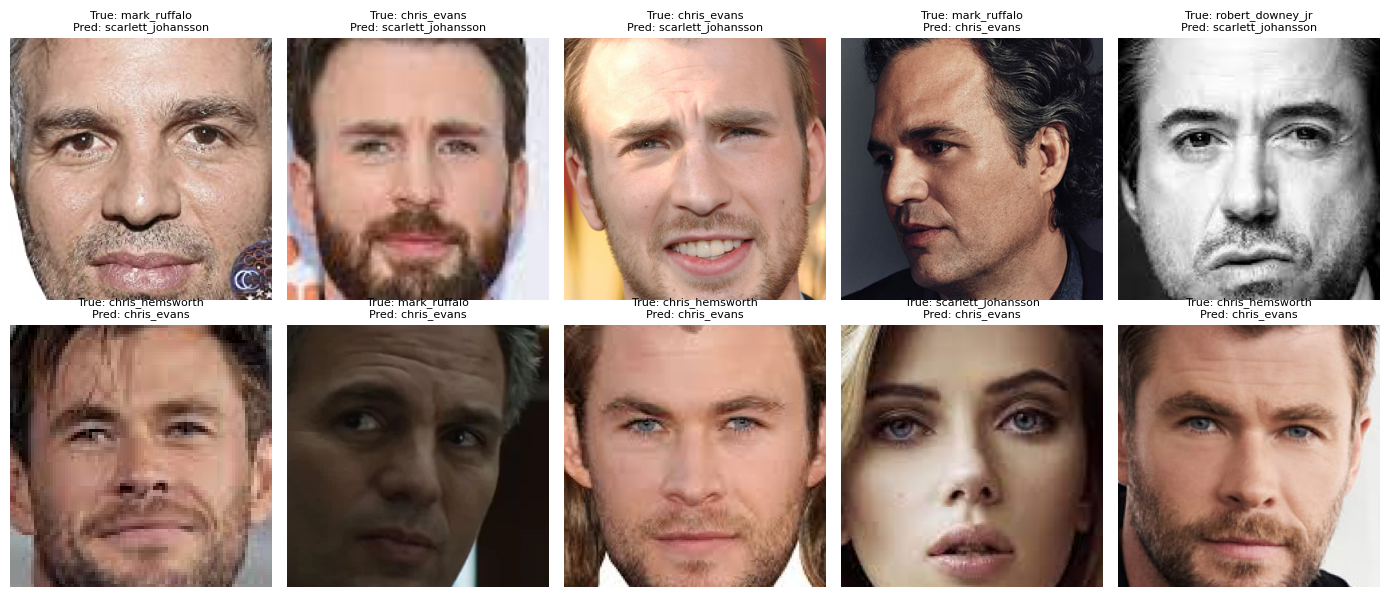

In [20]:
# Misclassified examples
wrong = np.where(y_true != y_pred)[0]
print(f'Misclassified: {len(wrong)} of {len(y_true)}')
show = wrong[:10]
if len(show):
    plt.figure(figsize=(14, 6))
    for i, idx in enumerate(show):
        plt.subplot(2, 5, i + 1)
        plt.imshow(Image.open(test_df.path.iloc[idx]).convert('RGB')); plt.axis('off')
        plt.title(f'True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}', fontsize=8)
    plt.tight_layout(); plt.show()

## 11. Improvement: Transfer Learning (MobileNetV2)
Faces are a hard task for a small from-scratch CNN. A pretrained backbone usually gives a large accuracy boost, so we train it and compare against the baseline.

In [21]:
base = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet')
base.trainable = False

inp = layers.Input(shape=IMG_SIZE + (3,))
x = augment(inp)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(len(class_names), activation='softmax')(x)
tl_model = models.Model(inp, out, name='avengers_mobilenetv2')

tl_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])

tl_cbs = [
    callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1),
]
h1 = tl_model.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight, callbacks=tl_cbs)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.1728 - loss: 2.1527 - val_accuracy: 0.3171 - val_loss: 1.4388 - learning_rate: 0.0010
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 226ms/step - accuracy: 0.2827 - loss: 1.6913 - val_accuracy: 0.4878 - val_loss: 1.2725 - learning_rate: 0.0010
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 144ms/step - accuracy: 0.3770 - loss: 1.3748 - val_accuracy: 0.5122 - val_loss: 1.1448 - learning_rate: 0.0010
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step - accuracy: 0.4869 - loss: 1.3012 - val_accuracy: 0.5366 - val_loss: 1.0526 - learning_rate: 0.0010
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 134ms/step - accuracy: 0.5393 - loss: 1.1415 - val_accuracy: 0.5366 - val_loss: 0.9790 - learning_rate: 0.0010
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 155ms/step - accuracy: 0.5759 - loss: 1.0598 - val_accuracy: 0.6098 - val_loss: 0.9482 - learning_rate: 0.0010
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 147ms/step - a

Epoch 1/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 513ms/step - accuracy: 0.4764 - loss: 1.4526 - val_accuracy: 0.7073 - val_loss: 0.6658 - learning_rate: 1.0000e-05
Epoch 2/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 223ms/step - accuracy: 0.5026 - loss: 1.3314 - val_accuracy: 0.7073 - val_loss: 0.6656 - learning_rate: 1.0000e-05
Epoch 3/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 287ms/step - accuracy: 0.5288 - loss: 1.2557 - val_accuracy: 0.7073 - val_loss: 0.6655 - learning_rate: 1.0000e-05
Epoch 4/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 260ms/step - accuracy: 0.5393 - loss: 1.2342 - val_accuracy: 0.7073 - val_loss: 0.6648 - learning_rate: 1.0000e-05
Epoch 5/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 189ms/step - accuracy: 0.5183 - loss: 1.2010 - val_accuracy: 0.7073 - val_loss: 0.6636 - learning_rate: 1.0000e-05
Epoch 6/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 180ms/step - accuracy: 0.6021 - loss: 1.0155 - val_accuracy: 0.7073 - val_loss: 0.6613 - learning_rate: 1.0000e-05
Epoch 7/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step - accuracy: 0.6021 - loss

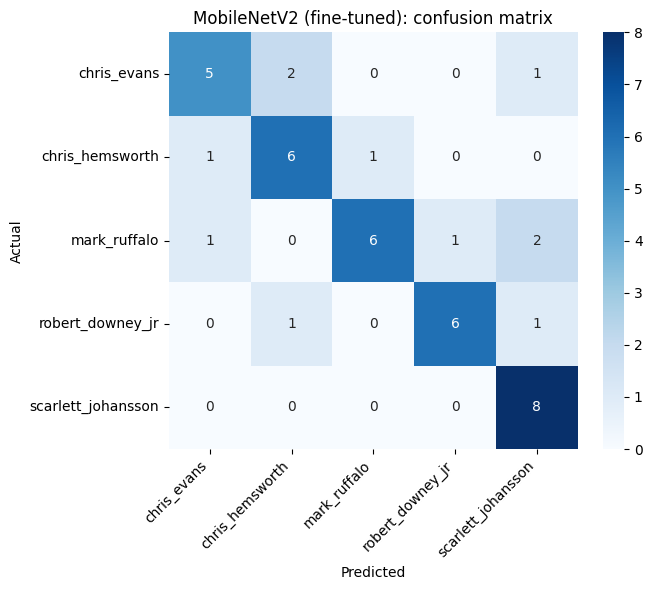

In [22]:
# Fine-tune the top of the backbone with a low learning rate
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

tl_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
h2 = tl_model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight, callbacks=tl_cbs)

y_true_tl, y_pred_tl, _ = evaluate(tl_model, 'MobileNetV2 (fine-tuned)')

## 12. Model Comparison & Save

,Model,Test accuracy
0,Custom CNN,0.190476
1,MobileNetV2 (fine-tuned),0.738095


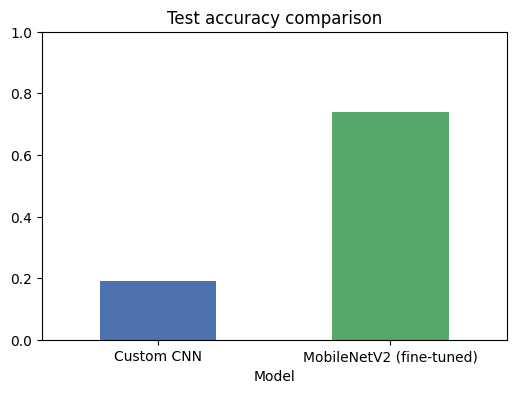

In [23]:
acc_cnn = (y_true == y_pred).mean()
acc_tl = (y_true_tl == y_pred_tl).mean()
res = pd.DataFrame({'Model': ['Custom CNN', 'MobileNetV2 (fine-tuned)'],
                    'Test accuracy': [acc_cnn, acc_tl]})
display(res)
res.plot.bar(x='Model', y='Test accuracy', legend=False, rot=0, color=['#4C72B0', '#55A868'], figsize=(6, 4))
plt.ylim(0, 1); plt.title('Test accuracy comparison'); plt.show()

In [24]:
save_dir = '/content/drive/MyDrive/CNN Capstone'
os.makedirs(save_dir, exist_ok=True)
model.save(f'{save_dir}/avengers_cnn.keras')
tl_model.save(f'{save_dir}/avengers_mobilenetv2.keras')
print('Models saved to', save_dir)

Models saved to /content/drive/MyDrive/CNN Capstone


## 13. Predict on a New Image

In [ ]:
from google.colab import files

best = tl_model if acc_tl >= acc_cnn else model
up = files.upload()
for name in up:
    img = tf.keras.utils.load_img(name, target_size=IMG_SIZE)
    arr = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)
    p = best.predict(arr, verbose=0)[0]
    plt.imshow(img); plt.axis('off')
    plt.title(f'{class_names[p.argmax()]} ({p.max():.1%})'); plt.show()

## 14. Conclusion
- Cleaned the dataset (corrupt, tiny and duplicate images removed) and used a stratified train/val/test split to avoid leakage.
- Built a custom CNN with BatchNorm, Dropout and augmentation, and compared it with a fine-tuned MobileNetV2.
- Evaluated with accuracy, per-class precision/recall/F1 and a confusion matrix, and inspected misclassified faces.

**Possible next steps:** collect more images per class, try EfficientNet / face-embedding models (FaceNet, ArcFace), and deploy with Streamlit or Gradio.